# Visualization: Employee Performance Analysis, INX Future Inc.

This notebook creates the figures used in the project summary and saves them as image files in `src/visualization/figures/`. It reads only processed data and model outputs; nothing is re-trained here.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path('../..').resolve()
ART = ROOT/'src'/'models'/'artifacts'
FIG = ROOT/'src'/'visualization'/'figures'; FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT/'data'/'processed'/'employee_clean.csv')
imp = pd.read_csv(ART/'feature_importance.csv')
comp = pd.read_csv(ART/'model_comparison.csv')
cm = pd.read_csv(ART/'test_confusion_matrix.csv', index_col=0)
oof = pd.read_csv(ART/'out_of_fold_predictions.csv')
meta = json.loads((ART/'model_metadata.json').read_text())
COL = {2:'#d1495b', 3:'#8d99ae', 4:'#2a9d8f'}
def save(name): plt.tight_layout(); plt.savefig(FIG/name, dpi=150, bbox_inches='tight'); plt.show()

## Figure 1: Distribution of performance ratings

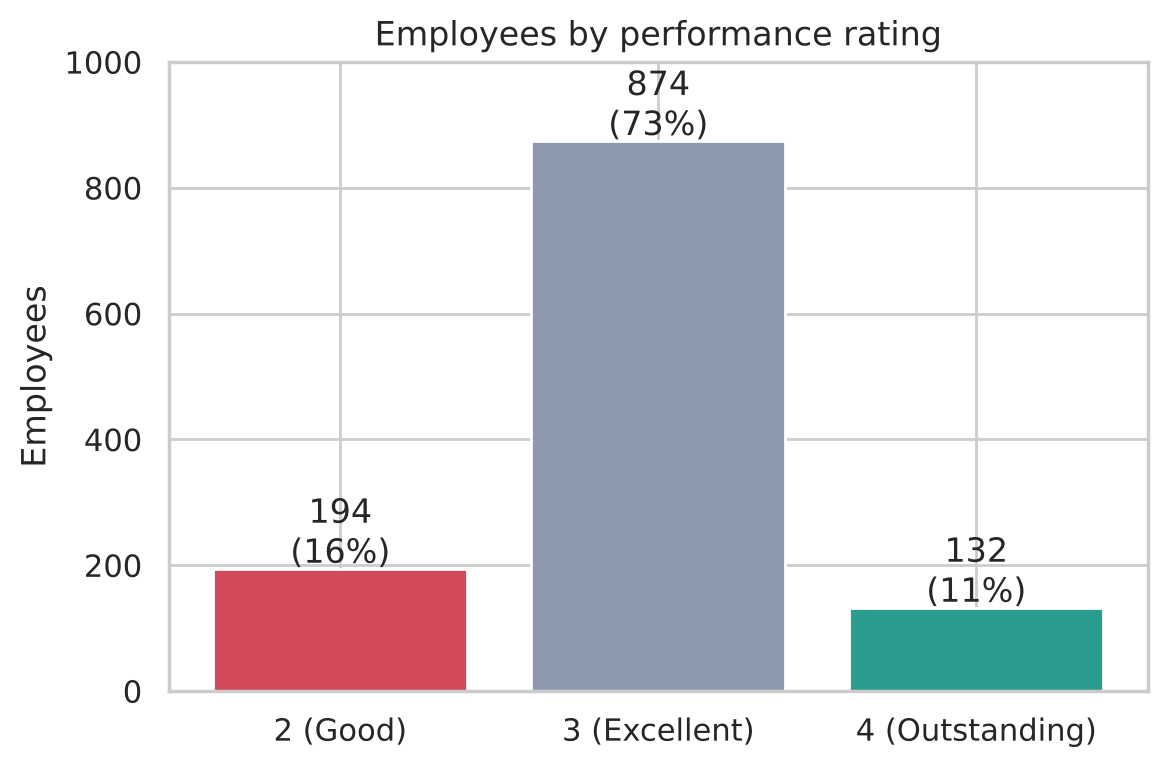

In [2]:
fig, ax = plt.subplots(figsize=(6,4))
c = df.PerformanceRating.value_counts().sort_index()
bars = ax.bar(['2 (Good)','3 (Excellent)','4 (Outstanding)'], c.values, color=[COL[i] for i in c.index])
for b,v in zip(bars,c.values): ax.text(b.get_x()+b.get_width()/2, v+10, f'{v}\n({100*v/len(df):.0f}%)', ha='center')
ax.set_ylabel('Employees'); ax.set_title('Employees by performance rating'); ax.set_ylim(0, 1000)
save('01_rating_distribution.png')

## Figure 2: Department-wise performance (required insight 1)

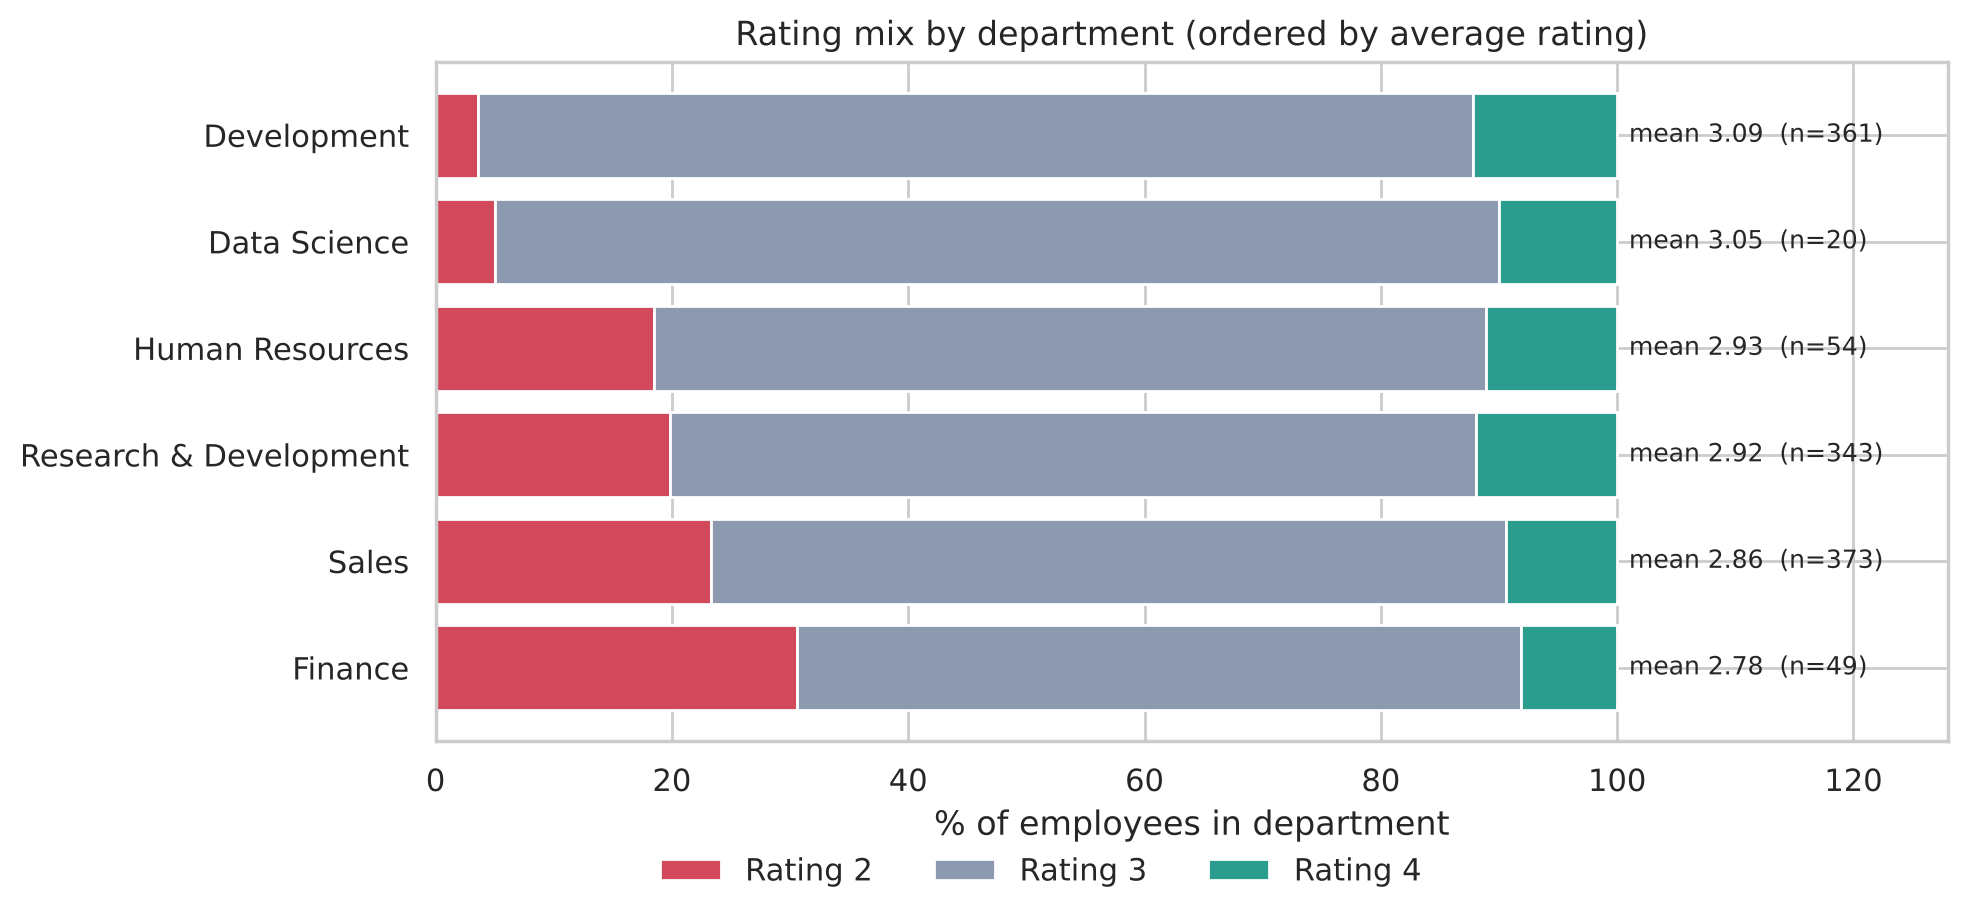

In [3]:
mix = pd.crosstab(df.EmpDepartment, df.PerformanceRating, normalize='index').mul(100)
order = df.groupby('EmpDepartment').PerformanceRating.mean().sort_values().index
mix = mix.loc[order]; means = df.groupby('EmpDepartment').PerformanceRating.mean().loc[order]; n = df.EmpDepartment.value_counts().loc[order]
fig, ax = plt.subplots(figsize=(10,4.8))
left = np.zeros(len(mix))
for r in [2,3,4]:
    ax.barh(mix.index, mix[r], left=left, color=COL[r], label=f'Rating {r}'); left += mix[r].values
for i,(d,m) in enumerate(means.items()): ax.text(101, i, f'mean {m:.2f}  (n={n[d]})', va='center', fontsize=9)
ax.set_xlim(0,128); ax.set_xlabel('% of employees in department'); ax.set_title('Rating mix by department (ordered by average rating)')
ax.legend(loc='upper center', bbox_to_anchor=(0.4,-0.13), ncol=3, frameon=False)
save('02_department_performance.png')

## Figure 3: Lower-performer share by job role

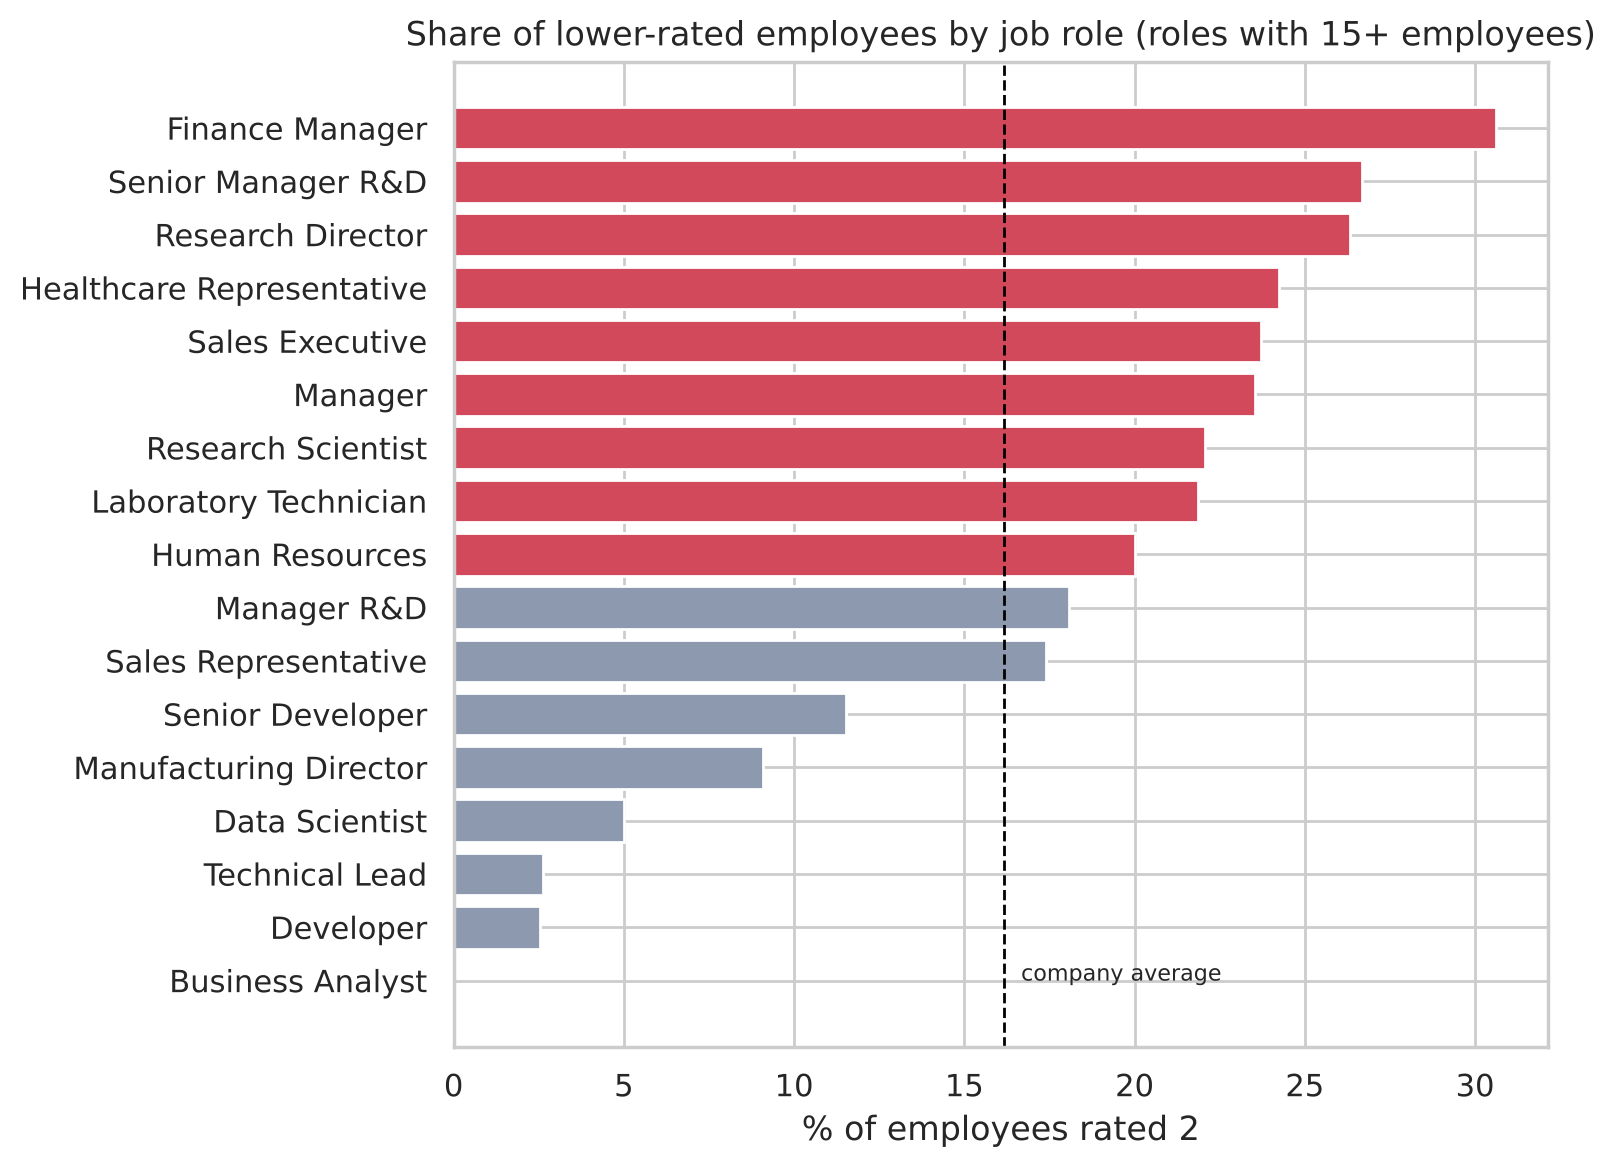

In [4]:
r = df.groupby('EmpJobRole').agg(n=('PerformanceRating','size'), low=('PerformanceRating', lambda s:100*(s==2).mean())).query('n>=15').sort_values('low')
fig, ax = plt.subplots(figsize=(8,6))
ax.barh(r.index, r.low, color=np.where(r.low>=20,'#d1495b','#8d99ae'))
ax.axvline(100*(df.PerformanceRating==2).mean(), ls='--', c='black', lw=1); ax.text(100*(df.PerformanceRating==2).mean()+.5, 0, 'company average', fontsize=8)
ax.set_xlabel('% of employees rated 2'); ax.set_title('Share of lower-rated employees by job role (roles with 15+ employees)')
save('03_job_role_low_performer_share.png')

## Figure 4: Top factors affecting performance (required insight 2)

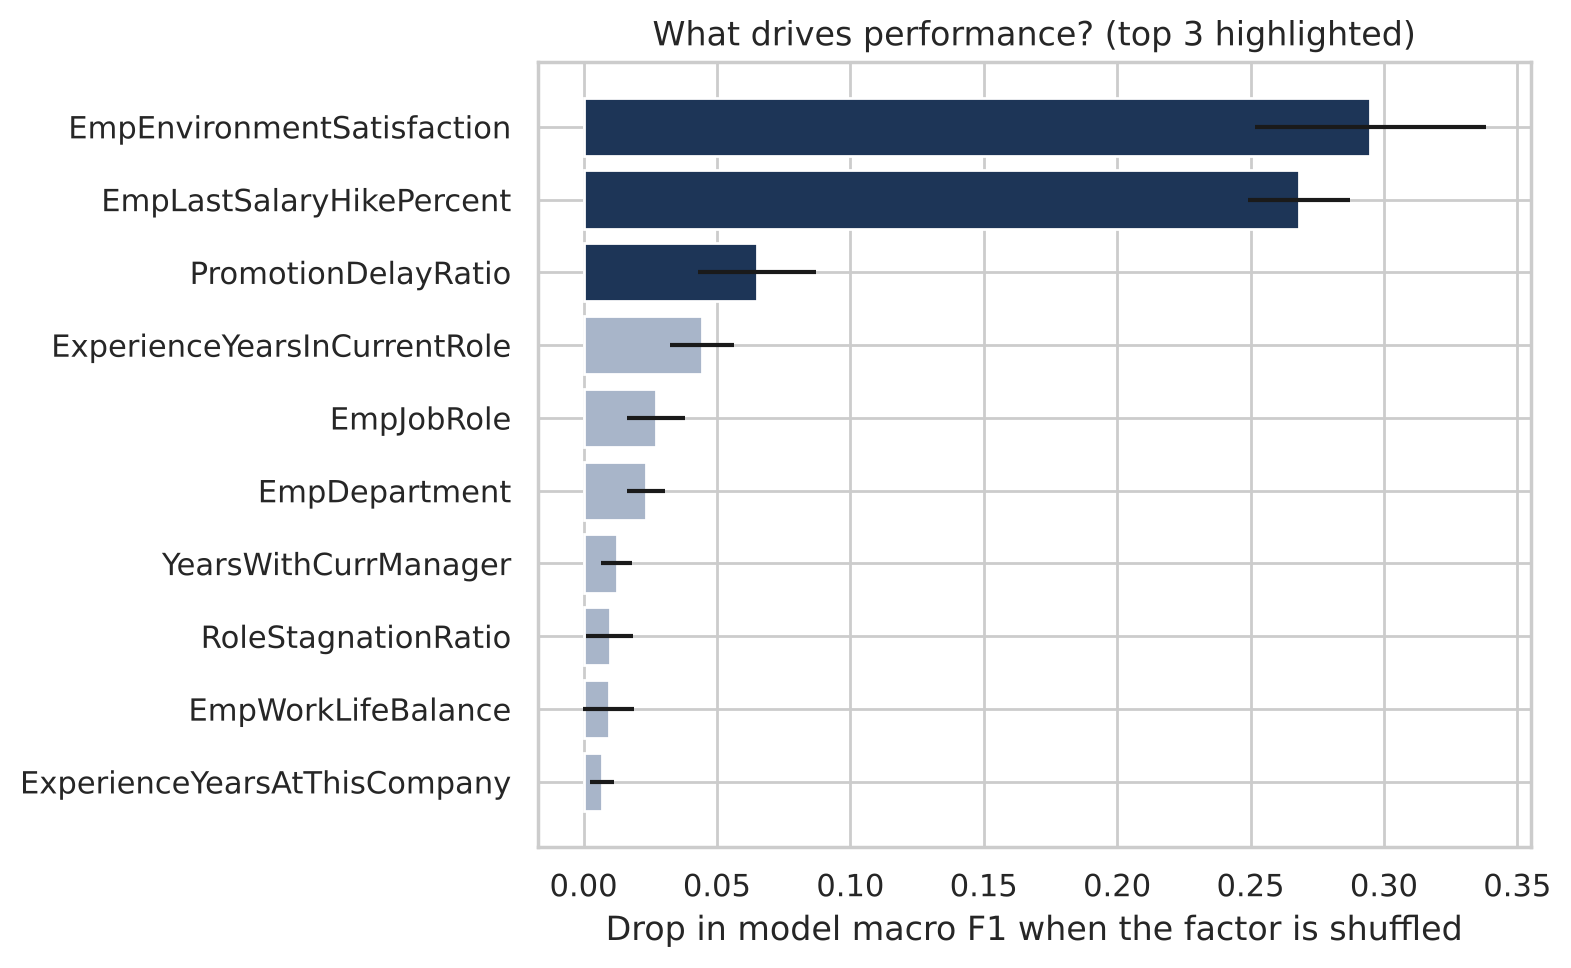

In [5]:
t = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,5))
colors = ['#1d3557' if f in meta['top3_factors'] else '#a8b5c9' for f in t.feature]
ax.barh(t.feature, t.permutation_importance, xerr=t['std'], color=colors)
ax.set_xlabel('Drop in model macro F1 when the factor is shuffled'); ax.set_title('What drives performance? (top 3 highlighted)')
save('04_top_factors.png')

## Figure 5: How the three key factors relate to rating

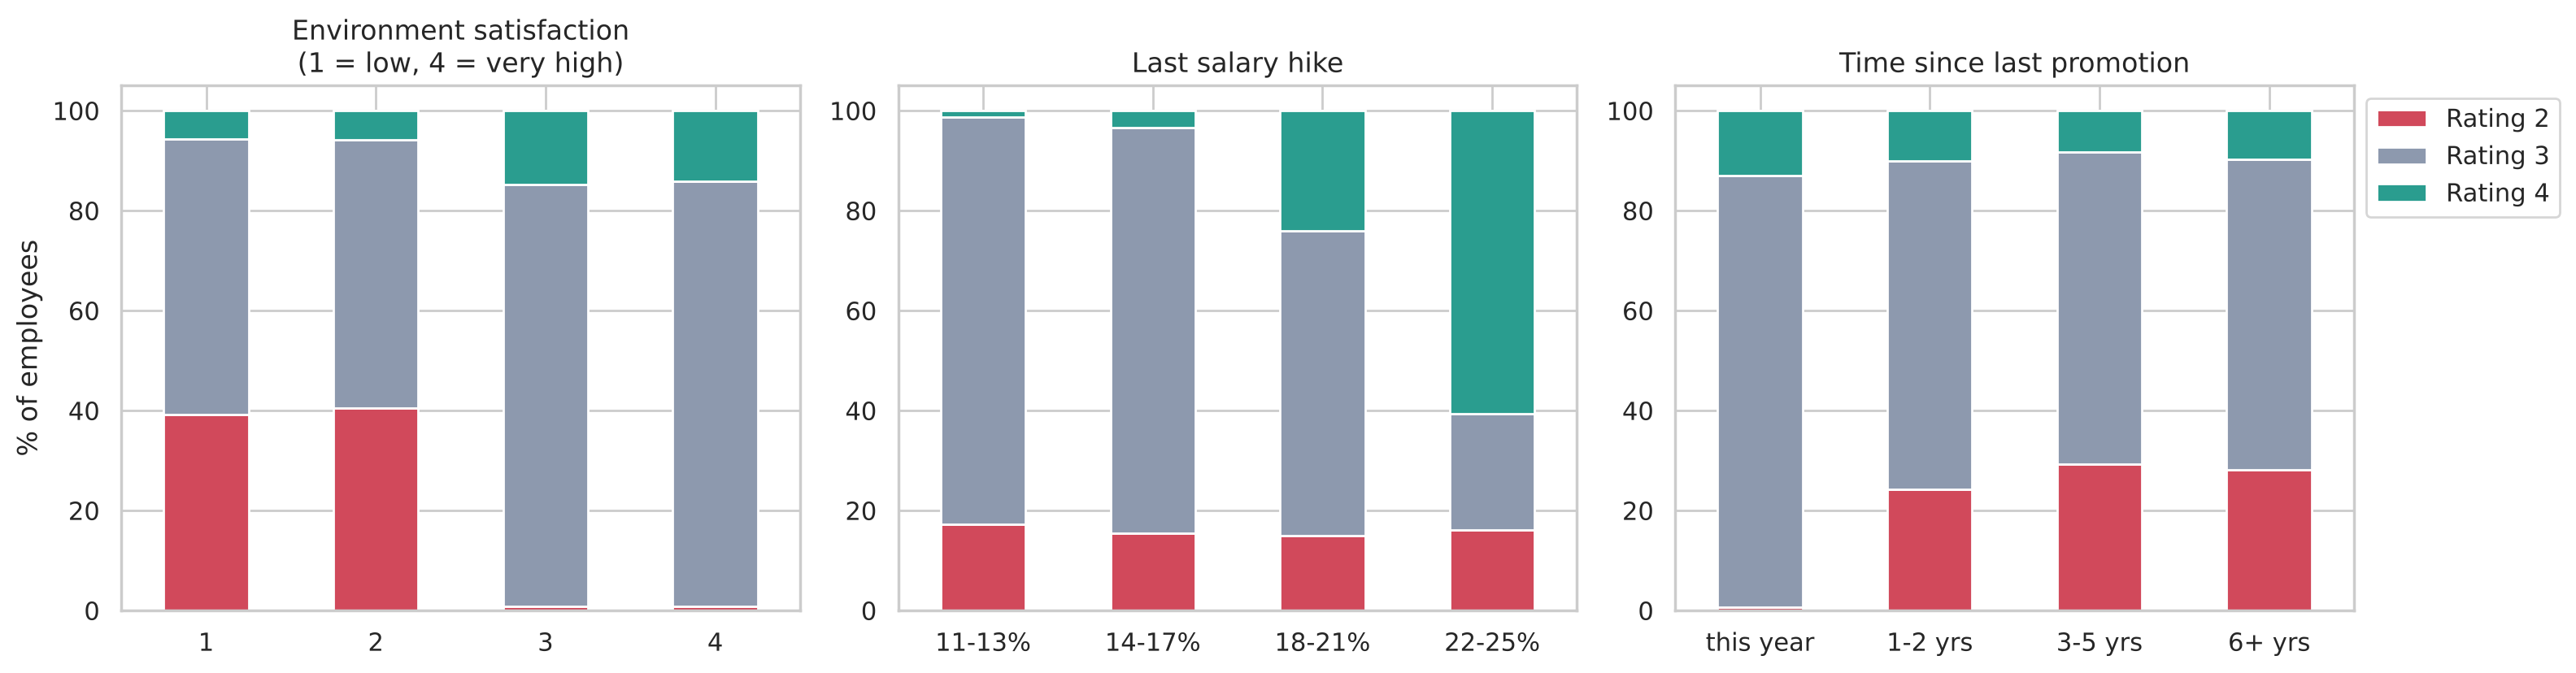

In [6]:
fig, axes = plt.subplots(1,3, figsize=(16,4.3))
a = pd.crosstab(df.EmpEnvironmentSatisfaction, df.PerformanceRating, normalize='index').mul(100)
a.plot(kind='bar', stacked=True, ax=axes[0], color=[COL[2],COL[3],COL[4]], legend=False, rot=0)
axes[0].set_title('Environment satisfaction\n(1 = low, 4 = very high)'); axes[0].set_ylabel('% of employees'); axes[0].set_xlabel('')
df['HikeBand'] = pd.cut(df.EmpLastSalaryHikePercent,[10,13,17,21,25],labels=['11-13%','14-17%','18-21%','22-25%'])
b = pd.crosstab(df.HikeBand, df.PerformanceRating, normalize='index').mul(100)
b.plot(kind='bar', stacked=True, ax=axes[1], color=[COL[2],COL[3],COL[4]], legend=False, rot=0); axes[1].set_title('Last salary hike'); axes[1].set_xlabel('')
df['PromoBand'] = pd.cut(df.YearsSinceLastPromotion,[-1,0,2,5,15],labels=['this year','1-2 yrs','3-5 yrs','6+ yrs'])
c = pd.crosstab(df.PromoBand, df.PerformanceRating, normalize='index').mul(100)
c.plot(kind='bar', stacked=True, ax=axes[2], color=[COL[2],COL[3],COL[4]], rot=0); axes[2].set_title('Time since last promotion'); axes[2].set_xlabel('')
axes[2].legend(['Rating 2','Rating 3','Rating 4'], loc='upper left', bbox_to_anchor=(1,1))
save('05_key_factors_vs_rating.png')

## Figure 6: Model comparison

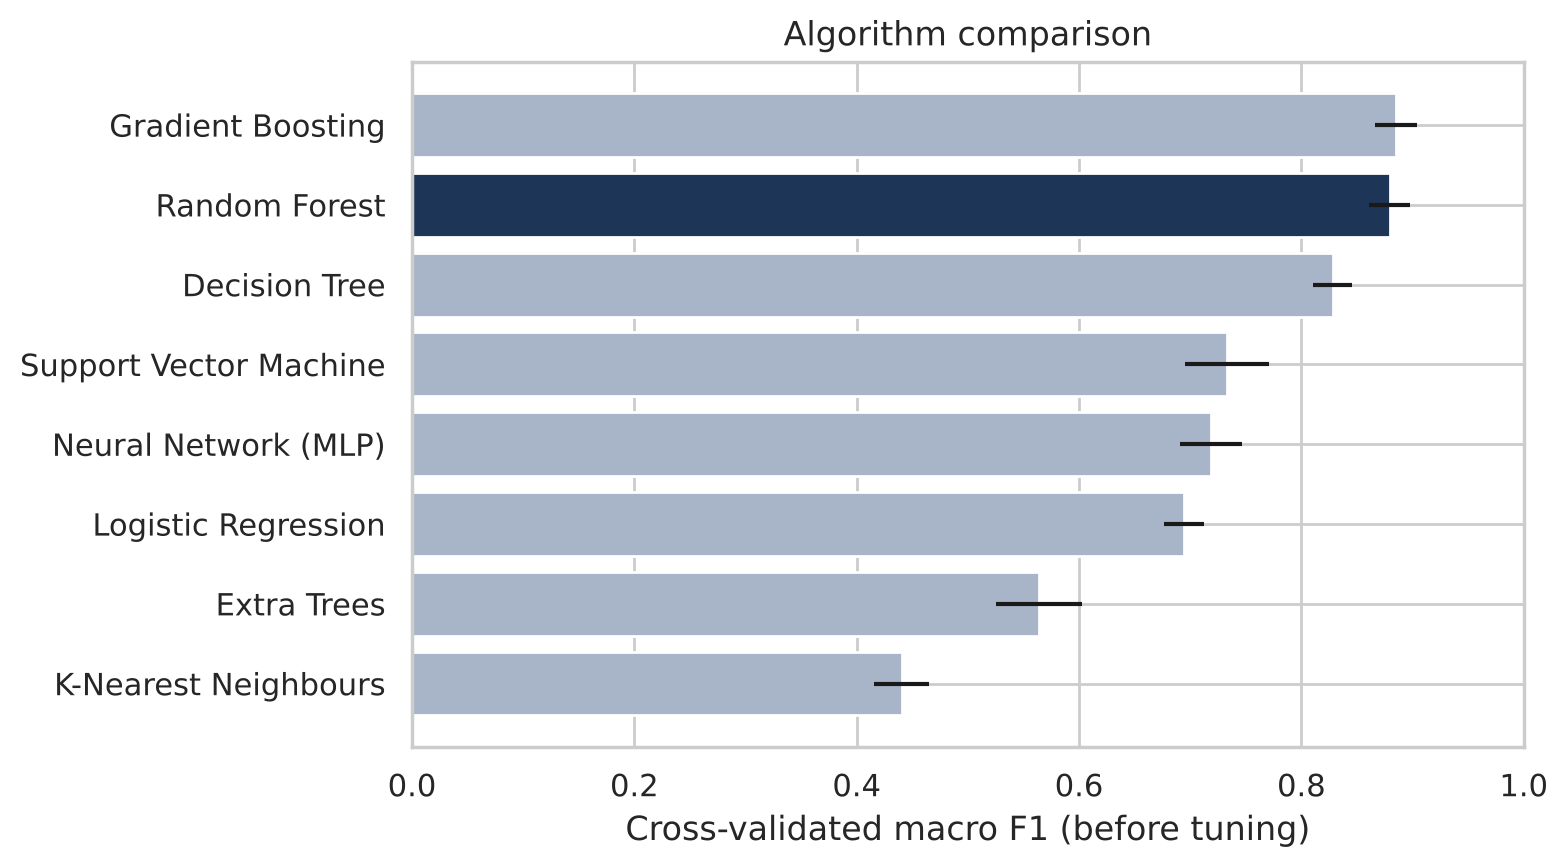

In [7]:
m = comp.sort_values('macro_F1')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(m.model, m.macro_F1, xerr=m.macro_F1_std, color=np.where(m.model==meta['metrics']['selected_model'],'#1d3557','#a8b5c9'))
ax.set_xlabel('Cross-validated macro F1 (before tuning)'); ax.set_title('Algorithm comparison'); ax.set_xlim(0,1)
save('06_model_comparison.png')

## Figure 7: Test-set confusion matrix

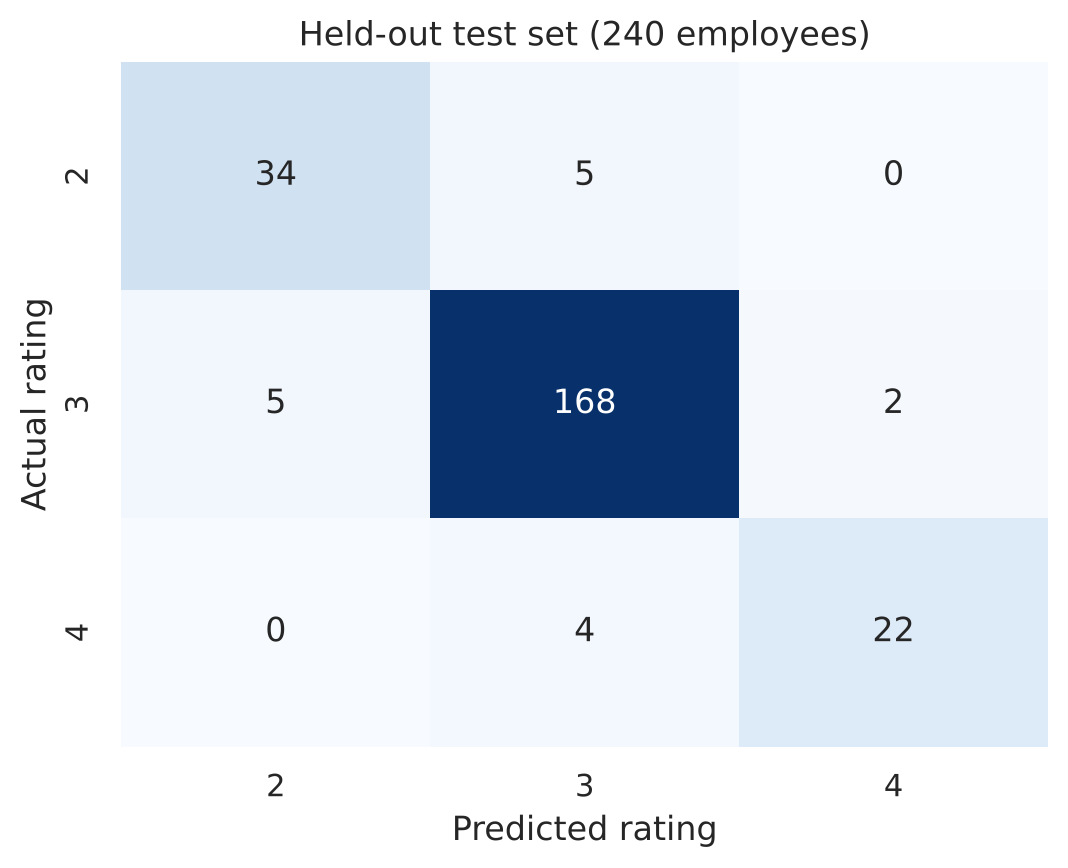

In [8]:
fig, ax = plt.subplots(figsize=(5.5,4.5))
sns.heatmap(cm.values, annot=True, fmt='d', cmap='Blues', xticklabels=[2,3,4], yticklabels=[2,3,4], ax=ax, cbar=False)
ax.set_xlabel('Predicted rating'); ax.set_ylabel('Actual rating'); ax.set_title('Held-out test set (240 employees)')
save('07_confusion_matrix.png')

## Figure 8: Why low environment satisfaction matters most

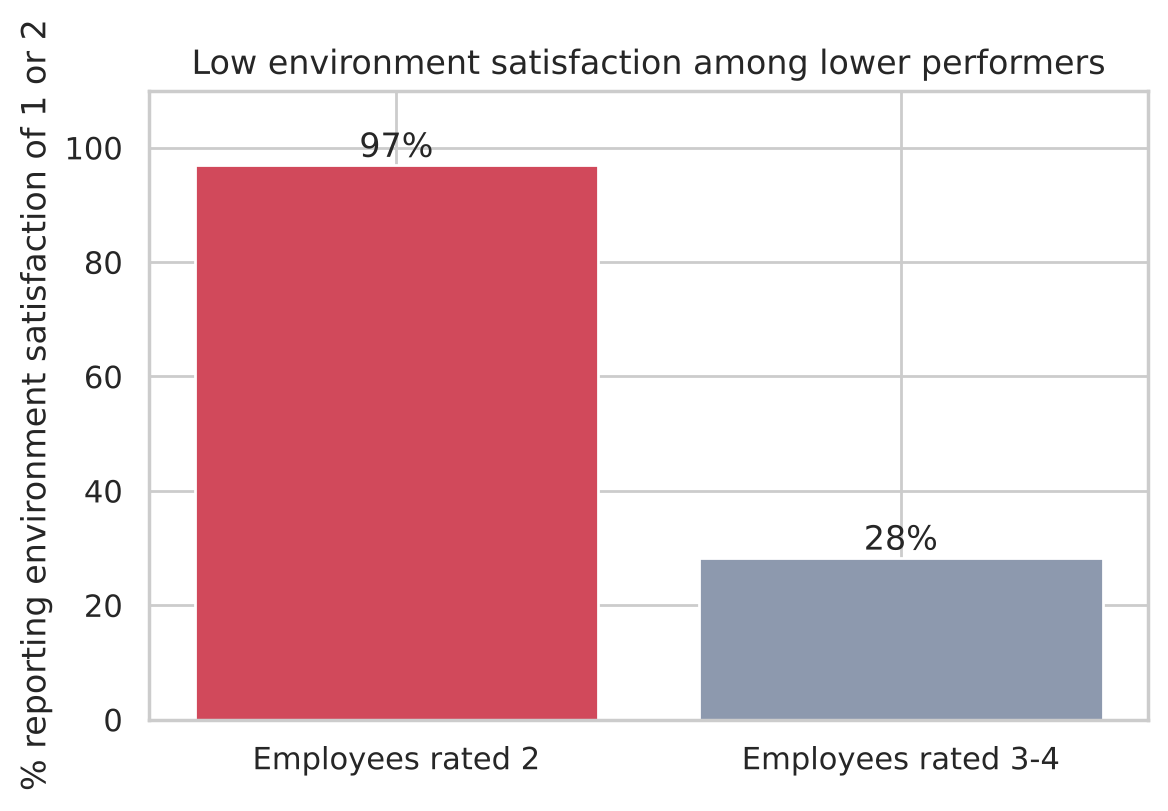

In [9]:
low = df[df.PerformanceRating==2]
share_low = 100*(low.EmpEnvironmentSatisfaction<=2).mean()
rest = df[df.PerformanceRating>2]; share_rest = 100*(rest.EmpEnvironmentSatisfaction<=2).mean()
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(['Employees rated 2','Employees rated 3-4'], [share_low, share_rest], color=[COL[2],COL[3]])
for b,v in zip(bars,[share_low,share_rest]): ax.text(b.get_x()+b.get_width()/2, v+1.5, f'{v:.0f}%', ha='center', fontsize=12)
ax.set_ylim(0,110); ax.set_ylabel('% reporting environment satisfaction of 1 or 2'); ax.set_title('Low environment satisfaction among lower performers')
save('08_environment_satisfaction_lower_performers.png')

## Figure 9: Watch-list share by department

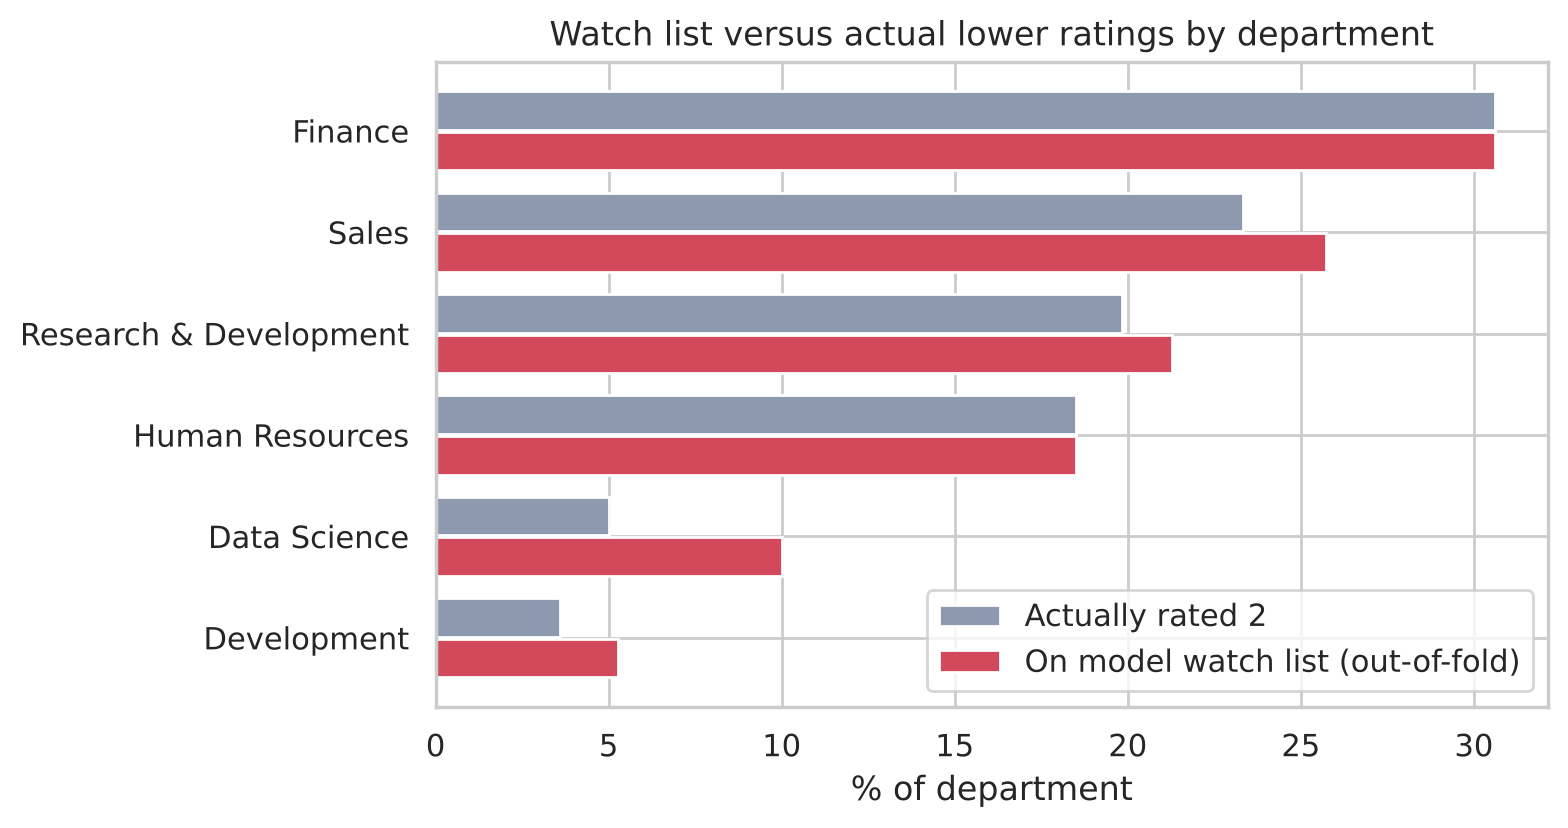

In [10]:
w = oof.assign(flag=oof.Prob_Rating2>=0.5).groupby('EmpDepartment').agg(n=('EmpNumber','size'), flagged=('flag','mean'), actual=('ActualRating', lambda s:(s==2).mean()))
w = w.mul([1,100,100]).sort_values('flagged')
fig, ax = plt.subplots(figsize=(8,4.3)); y = np.arange(len(w))
ax.barh(y+.2, w.actual, height=.38, color=COL[3], label='Actually rated 2'); ax.barh(y-.2, w.flagged, height=.38, color=COL[2], label='On model watch list (out-of-fold)')
ax.set_yticks(y); ax.set_yticklabels(w.index); ax.set_xlabel('% of department'); ax.legend(); ax.set_title('Watch list versus actual lower ratings by department')
save('09_watch_list_by_department.png')

In [11]:
print(sorted(p.name for p in FIG.iterdir()))

['01_rating_distribution.png', '02_department_performance.png', '03_job_role_low_performer_share.png', '04_top_factors.png', '05_key_factors_vs_rating.png', '06_model_comparison.png', '07_confusion_matrix.png', '08_environment_satisfaction_lower_performers.png', '09_watch_list_by_department.png']
